# Bogoliubov waves in the measured Josephson array

The physical envelope is $A e^{i(q_0^\mathrm{R} n-\omega_0 t)}$. Set $d=\Omega/2\pi$. The probe at $f_0+d$ multiplies $e^{-i\Omega T}$. The physical idler at $f_0-d$ multiplies $e^{+i\Omega T}$ and is the conjugate of the second propagated coefficient. The probe phase is pump-on over pump-off. The idler includes the pump phase.

The notebook uses Theory.jl and Build.jl from the same folder. Start Julia with the project in this directory and instantiate the project once if needed. The preview cell evaluates one case. Run **julia --project=. --threads=auto Build.jl** and then **julia --project=. --threads=auto BuildMaps.jl** to regenerate the dense sweeps and shared 401 × 401 maps. The paired Python scripts render the atlas and populate the browser viewer.

In [ ]:
using JSON
include(joinpath(pwd(), "Build.jl"))
const theory = BogoliubovTheory

fit_name = "selected17"
pump_GHz = 5.0
loss_tangent = 0.0027
order = 0  # Full dispersion. Use 2, 3, 4, 5 or 6 for a Taylor model.
chip_power_dBm = -104.5
p = theory.setup(pump_GHz, theory.PARAMS["fits"][fit_name], loss_tangent)
rho = theory.rhoin(chip_power_dBm, p)
hi = theory.healing(rho, p, order)
rho_out, theta_out = theory.pump(theory.N, rho, p)
ho = theory.healing(rho_out, p, order)
(; inlet_MHz=1000hi, outlet_MHz=1000ho, theta_out,
   valid=theory.validity(p,order))

## Evolve one probe and its idler

Write $\Delta_\pm=q(f_0\pm d)-q(f_0)\mp d\,\operatorname{Re}q'(f_0)$. In the pump frame, $\Phi=(u,v)^{\mathsf T}$ satisfies $\partial_n\Phi=-iH(n)\Phi$ with
$$
H(n)=\begin{pmatrix}
-\Delta_+-\operatorname{Re}\mu-i(\alpha+2\operatorname{Im}\mu)&-\mu\\
\mu^*&\Delta_-^*+\operatorname{Re}\mu-i(\alpha+2\operatorname{Im}\mu)
\end{pmatrix}.
$$
The initial state is $(1,0)^{\mathsf T}$. The physical probe and idler at the output are $e^{i\theta_p}u$ and $e^{i\theta_p}v^*$. Computing a phase at one detuning yields a principal argument. The sweep below constructs the unwrapped phase from the full grid.

In [ ]:
d = hi
Δplus, Δminus = theory.delta(d,p,order), theory.delta(-d,p,order)
u, v, steps, converged = theory.solve(Δplus,Δminus,rho,p)
(; physical_probe=cis(theta_out)*u, physical_idler=cis(theta_out)*conj(v),
   steps, converged)

## Unwrapped frequency cuts

The dense grid covers both signs of detuning and places at least 2,401 samples in the dedicated healing window. The lossless idler index counts $KN/\pi$ crossings. Break the line at each index change. The lossy lift tracks phase residuals from the pump frequency after removing the known odd propagation phase. Phases below the amplitude floor are masked.

In [ ]:
grid = spectral_nodes(p, order, min(5hi,theory.span(p));minimum=1200)
probe_phase, idler_phase, probe_dB, idler_dB, idler_nodes, max_steps, failures =
    spectrum(grid,p,order,chip_power_dBm)
@assert failures == 0
(; frequencies=length(grid), max_steps, min_detuning_MHz=1000first(grid),
   max_detuning_MHz=1000last(grid), inlet_healing_MHz=1000hi)

## Figures and checks

The examples below are embedded outputs from the calculated settings. The browser reads the same arrays for maps, surfaces and cuts.

- All_Maps.pdf shows signed 2D maps and the requested chip-power range.
- All_Response_Cuts.pdf shows full-band and inlet healing zooms.
- Circuit_and_Order_Comparison.pdf and Circuit_Diagnostics.pdf show coefficient, order, and pump checks.
- Validation.pdf shows independent integration and the optical comparisons.


In [ ]:
struct FigurePNG
    bytes::Vector{UInt8}
end
Base.show(io::IO, ::MIME"image/png", image::FigurePNG) = write(io, image.bytes)
Base.show(io::IO, image::FigurePNG) = print(io, "PNG figure (", length(image.bytes), " bytes)")


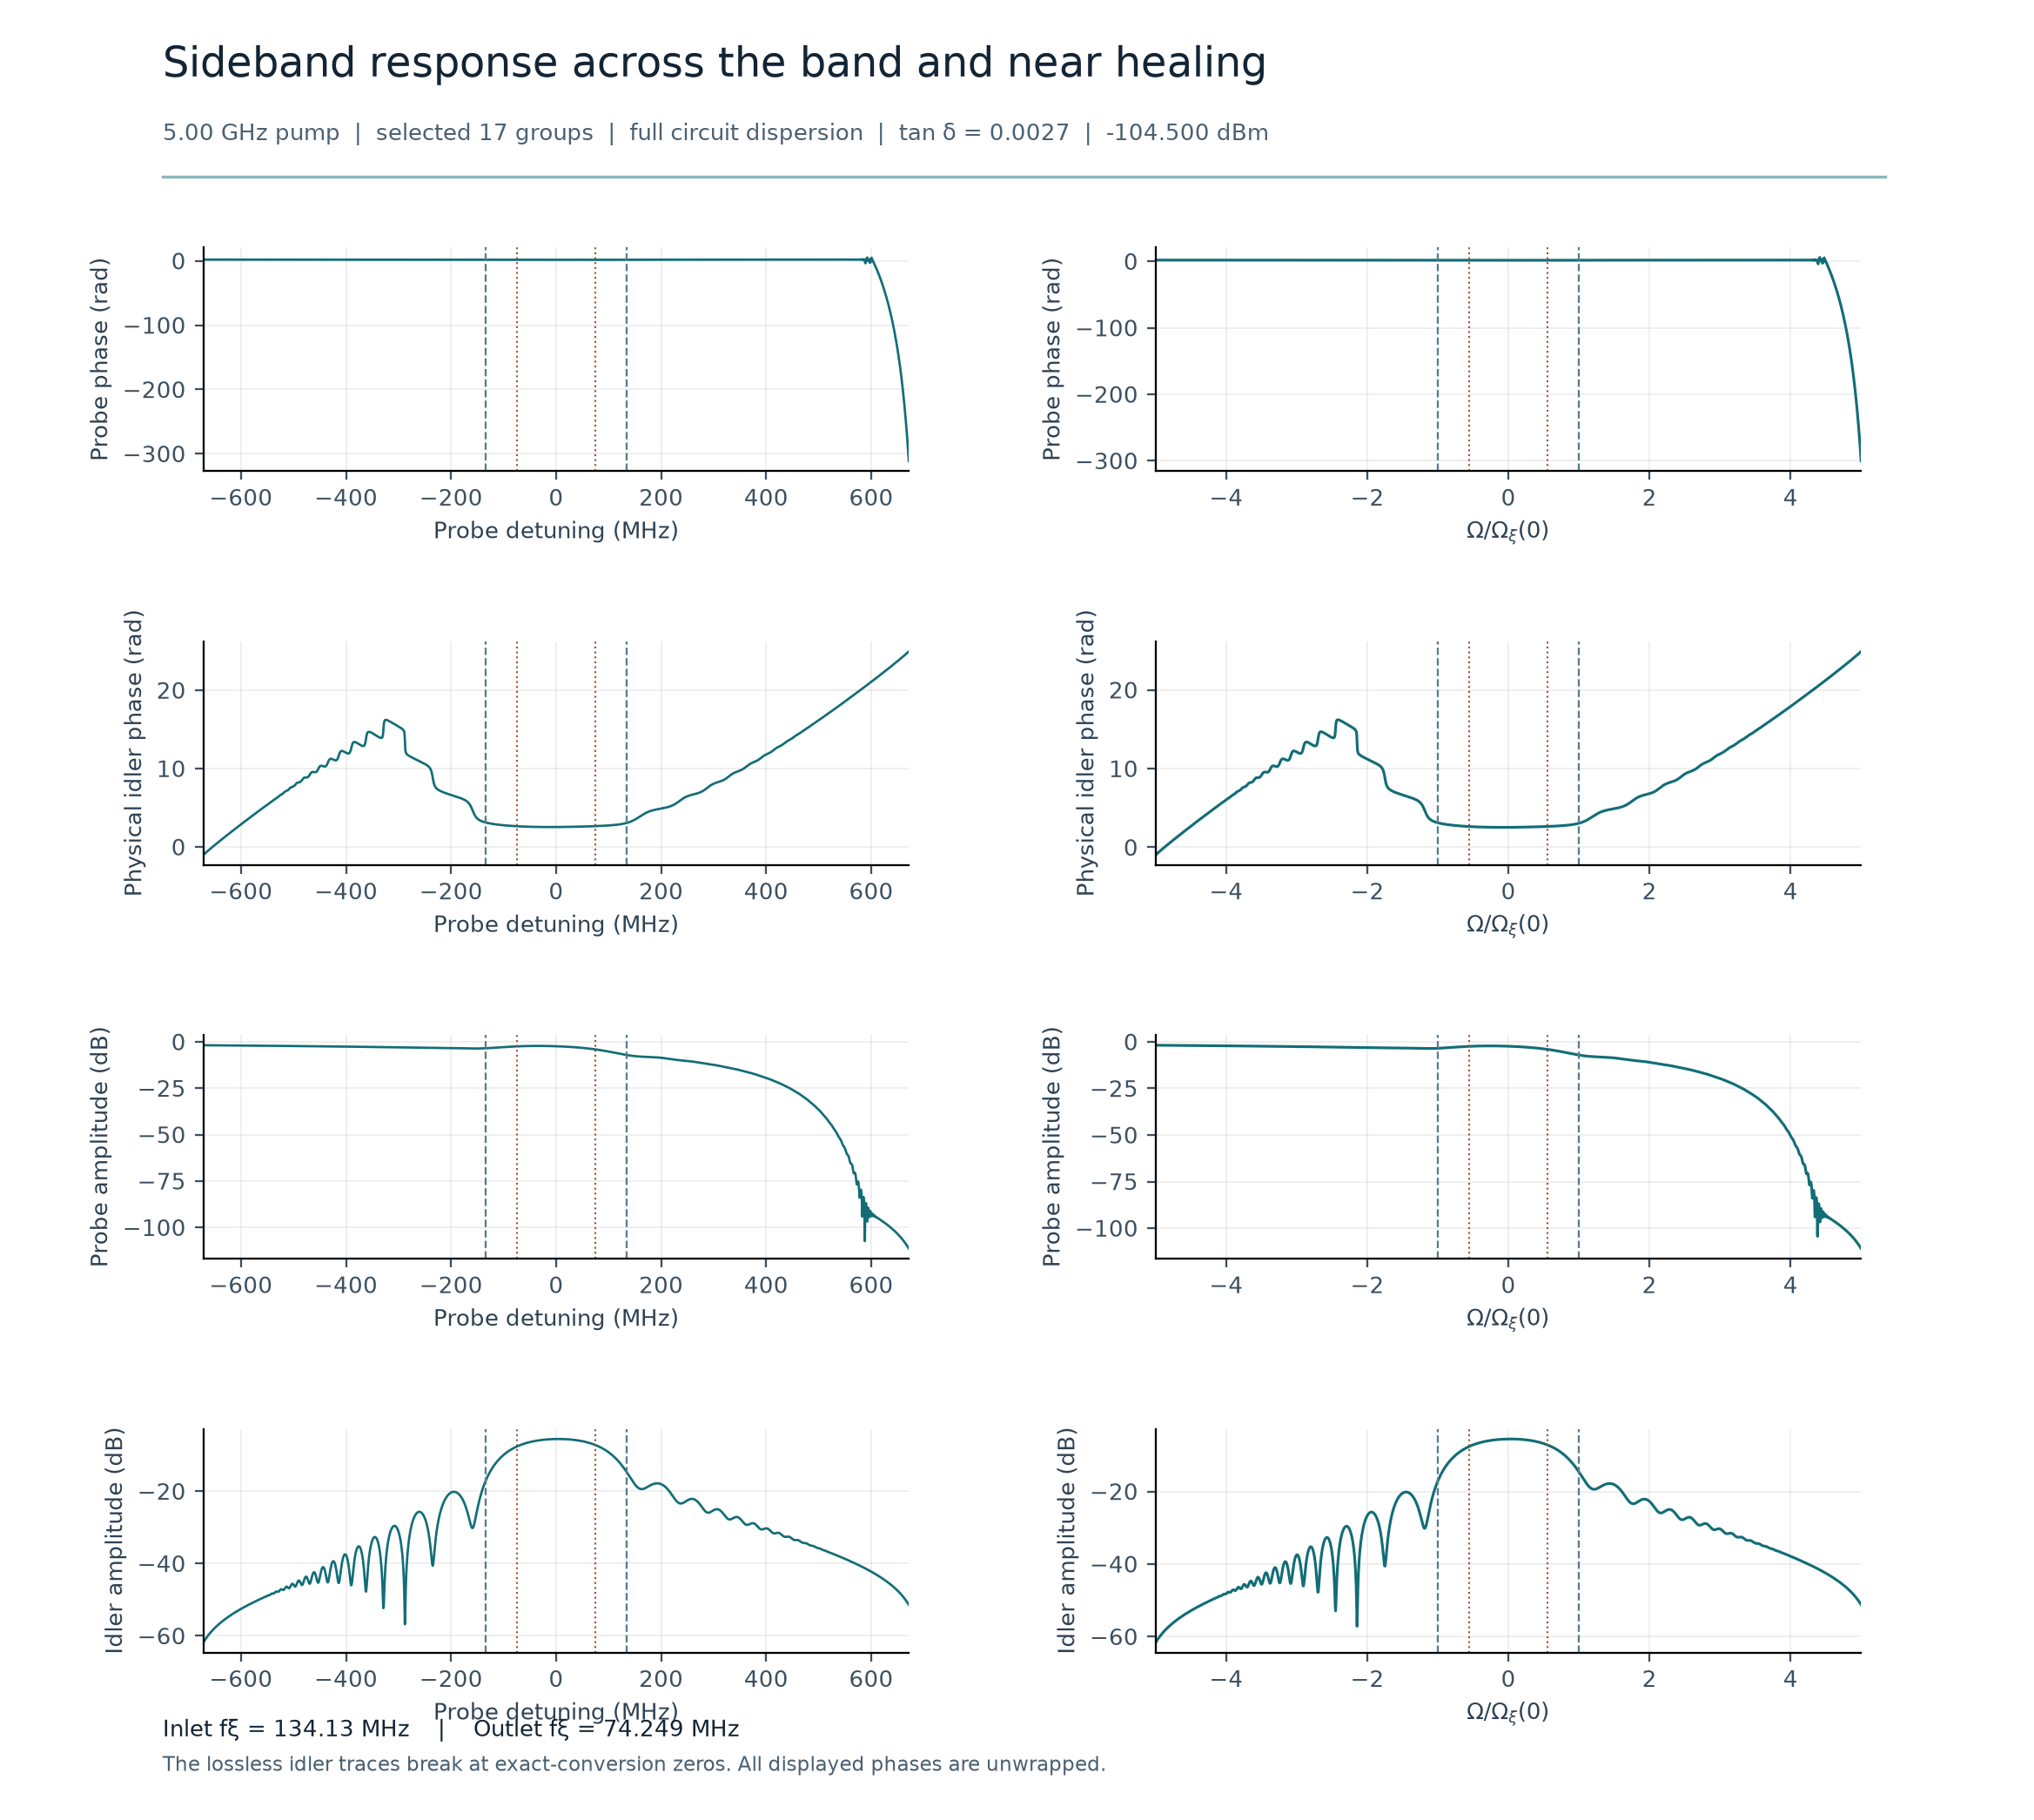

In [ ]:
display(FigurePNG(read(joinpath(pwd(), "Example_Cuts.png"))))

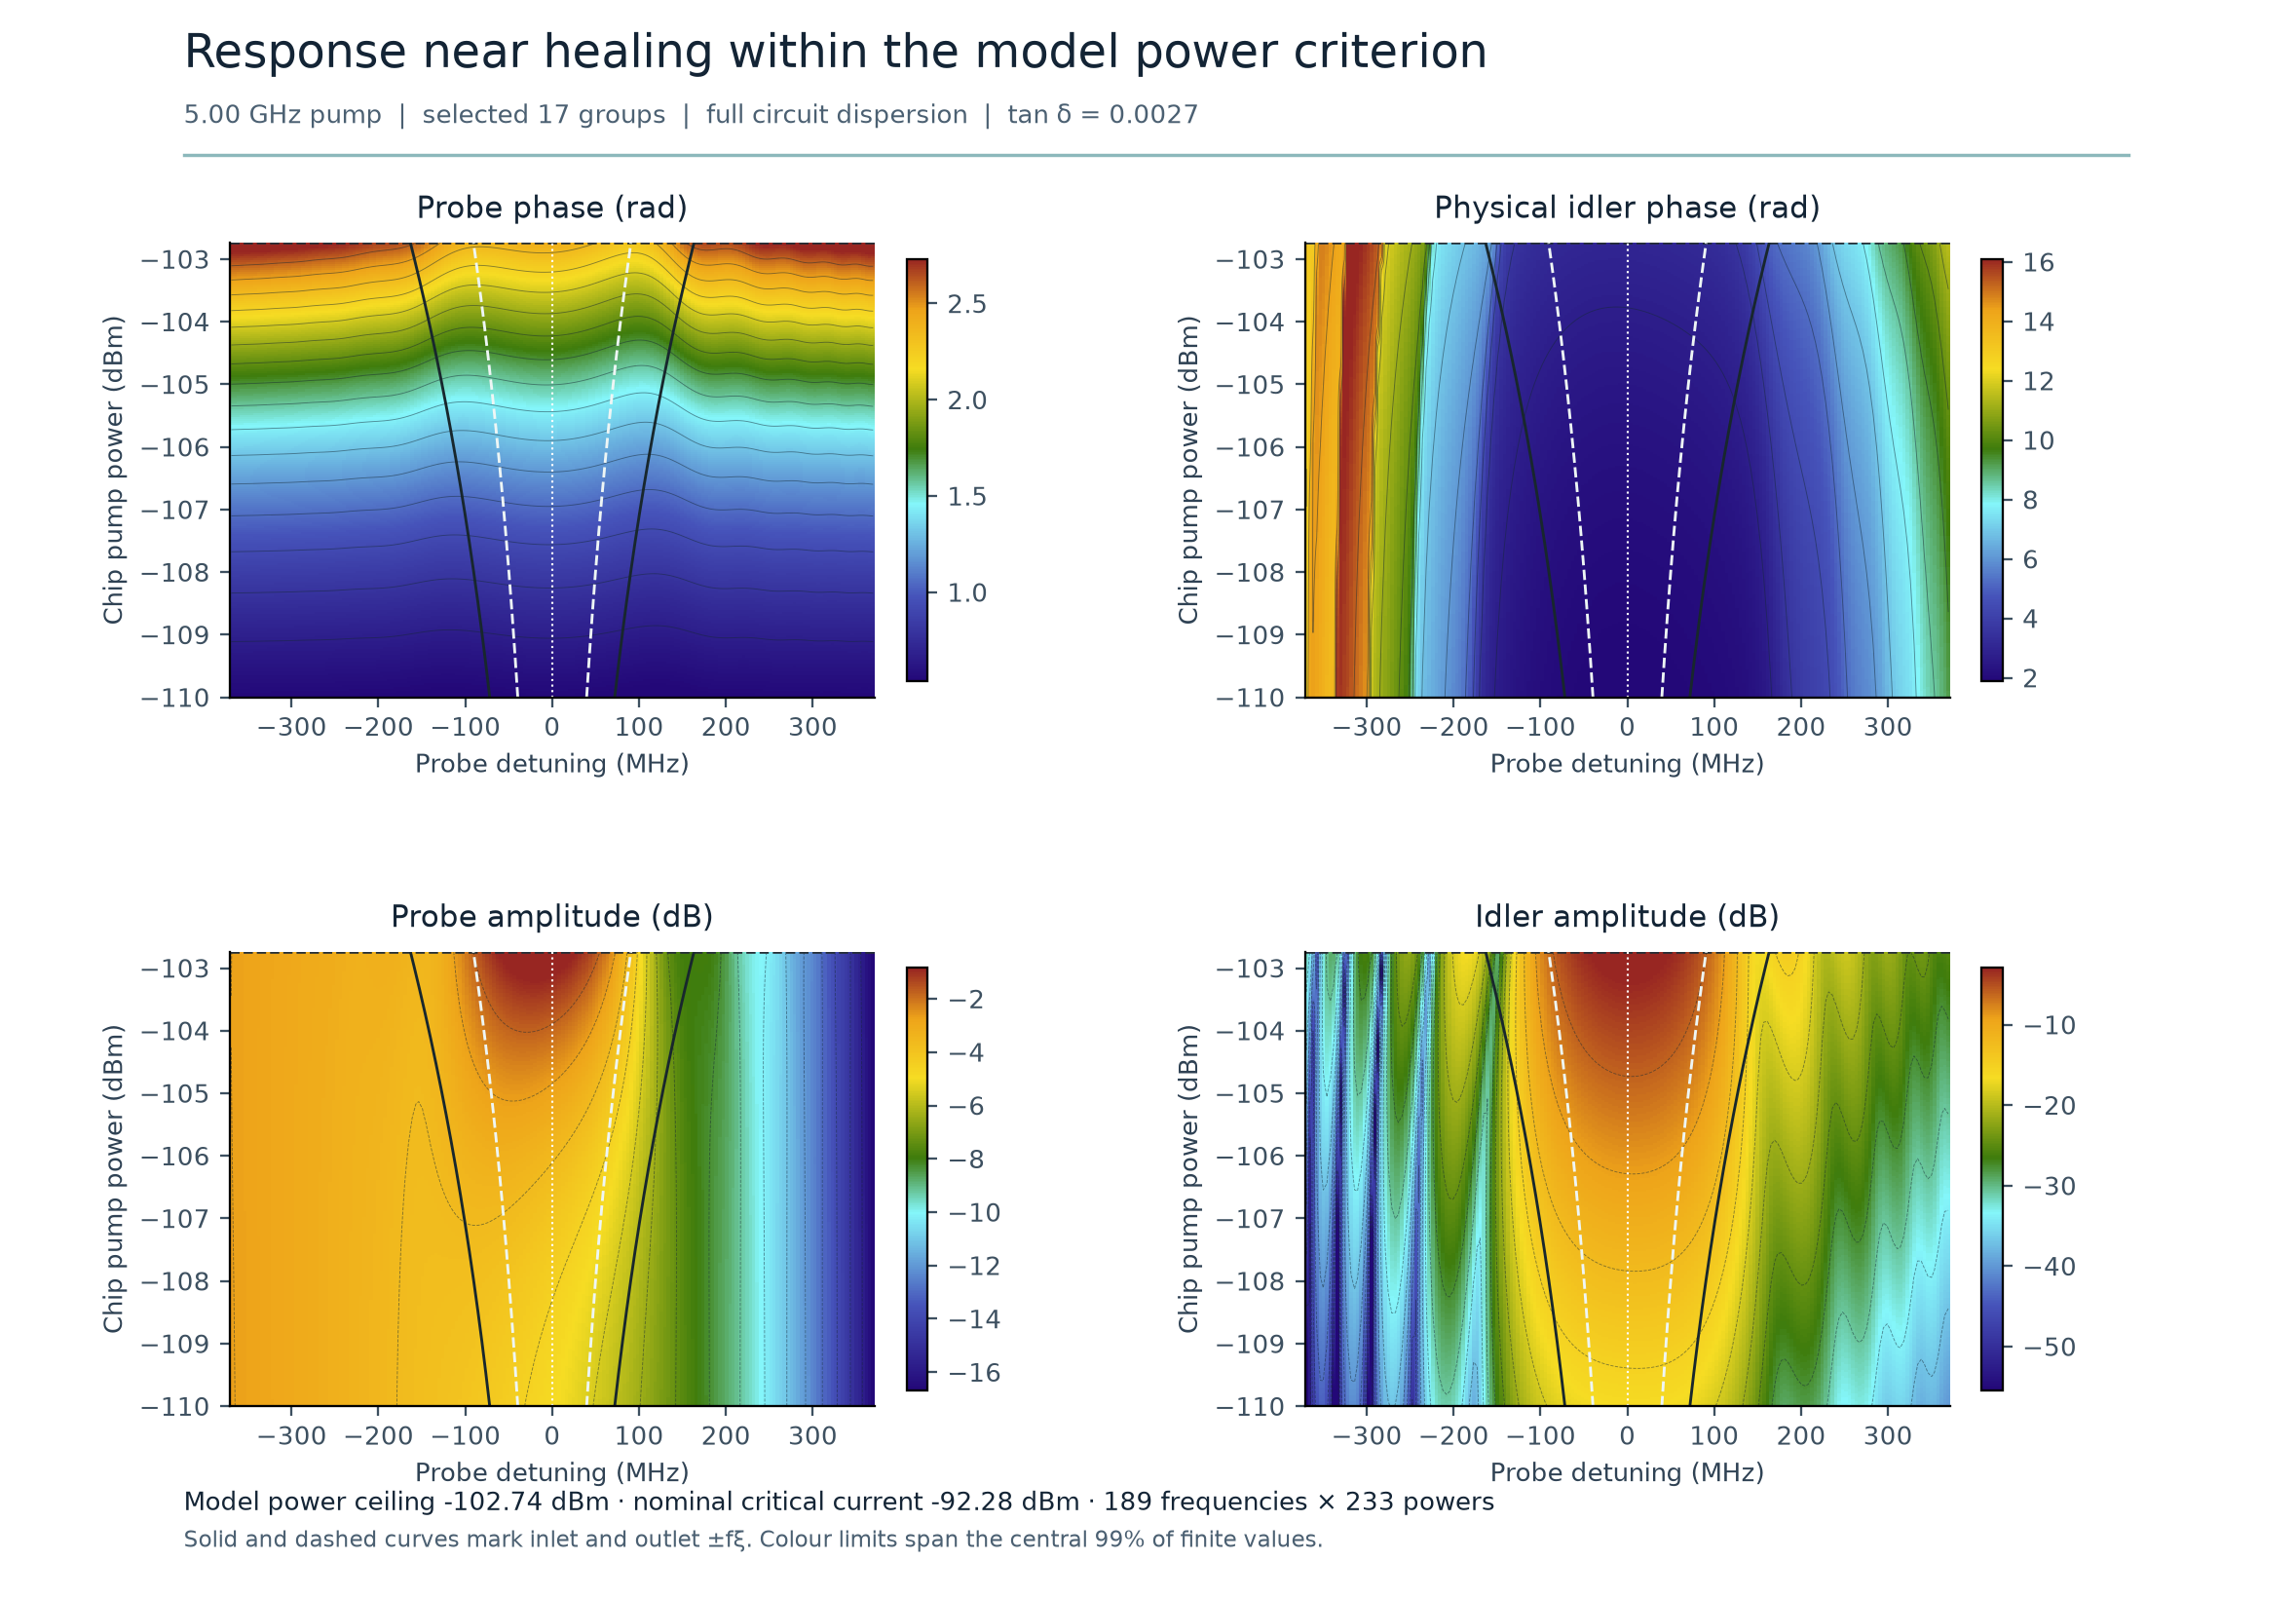

In [ ]:
display(FigurePNG(read(joinpath(pwd(), "Example_Healing_Maps.png"))))

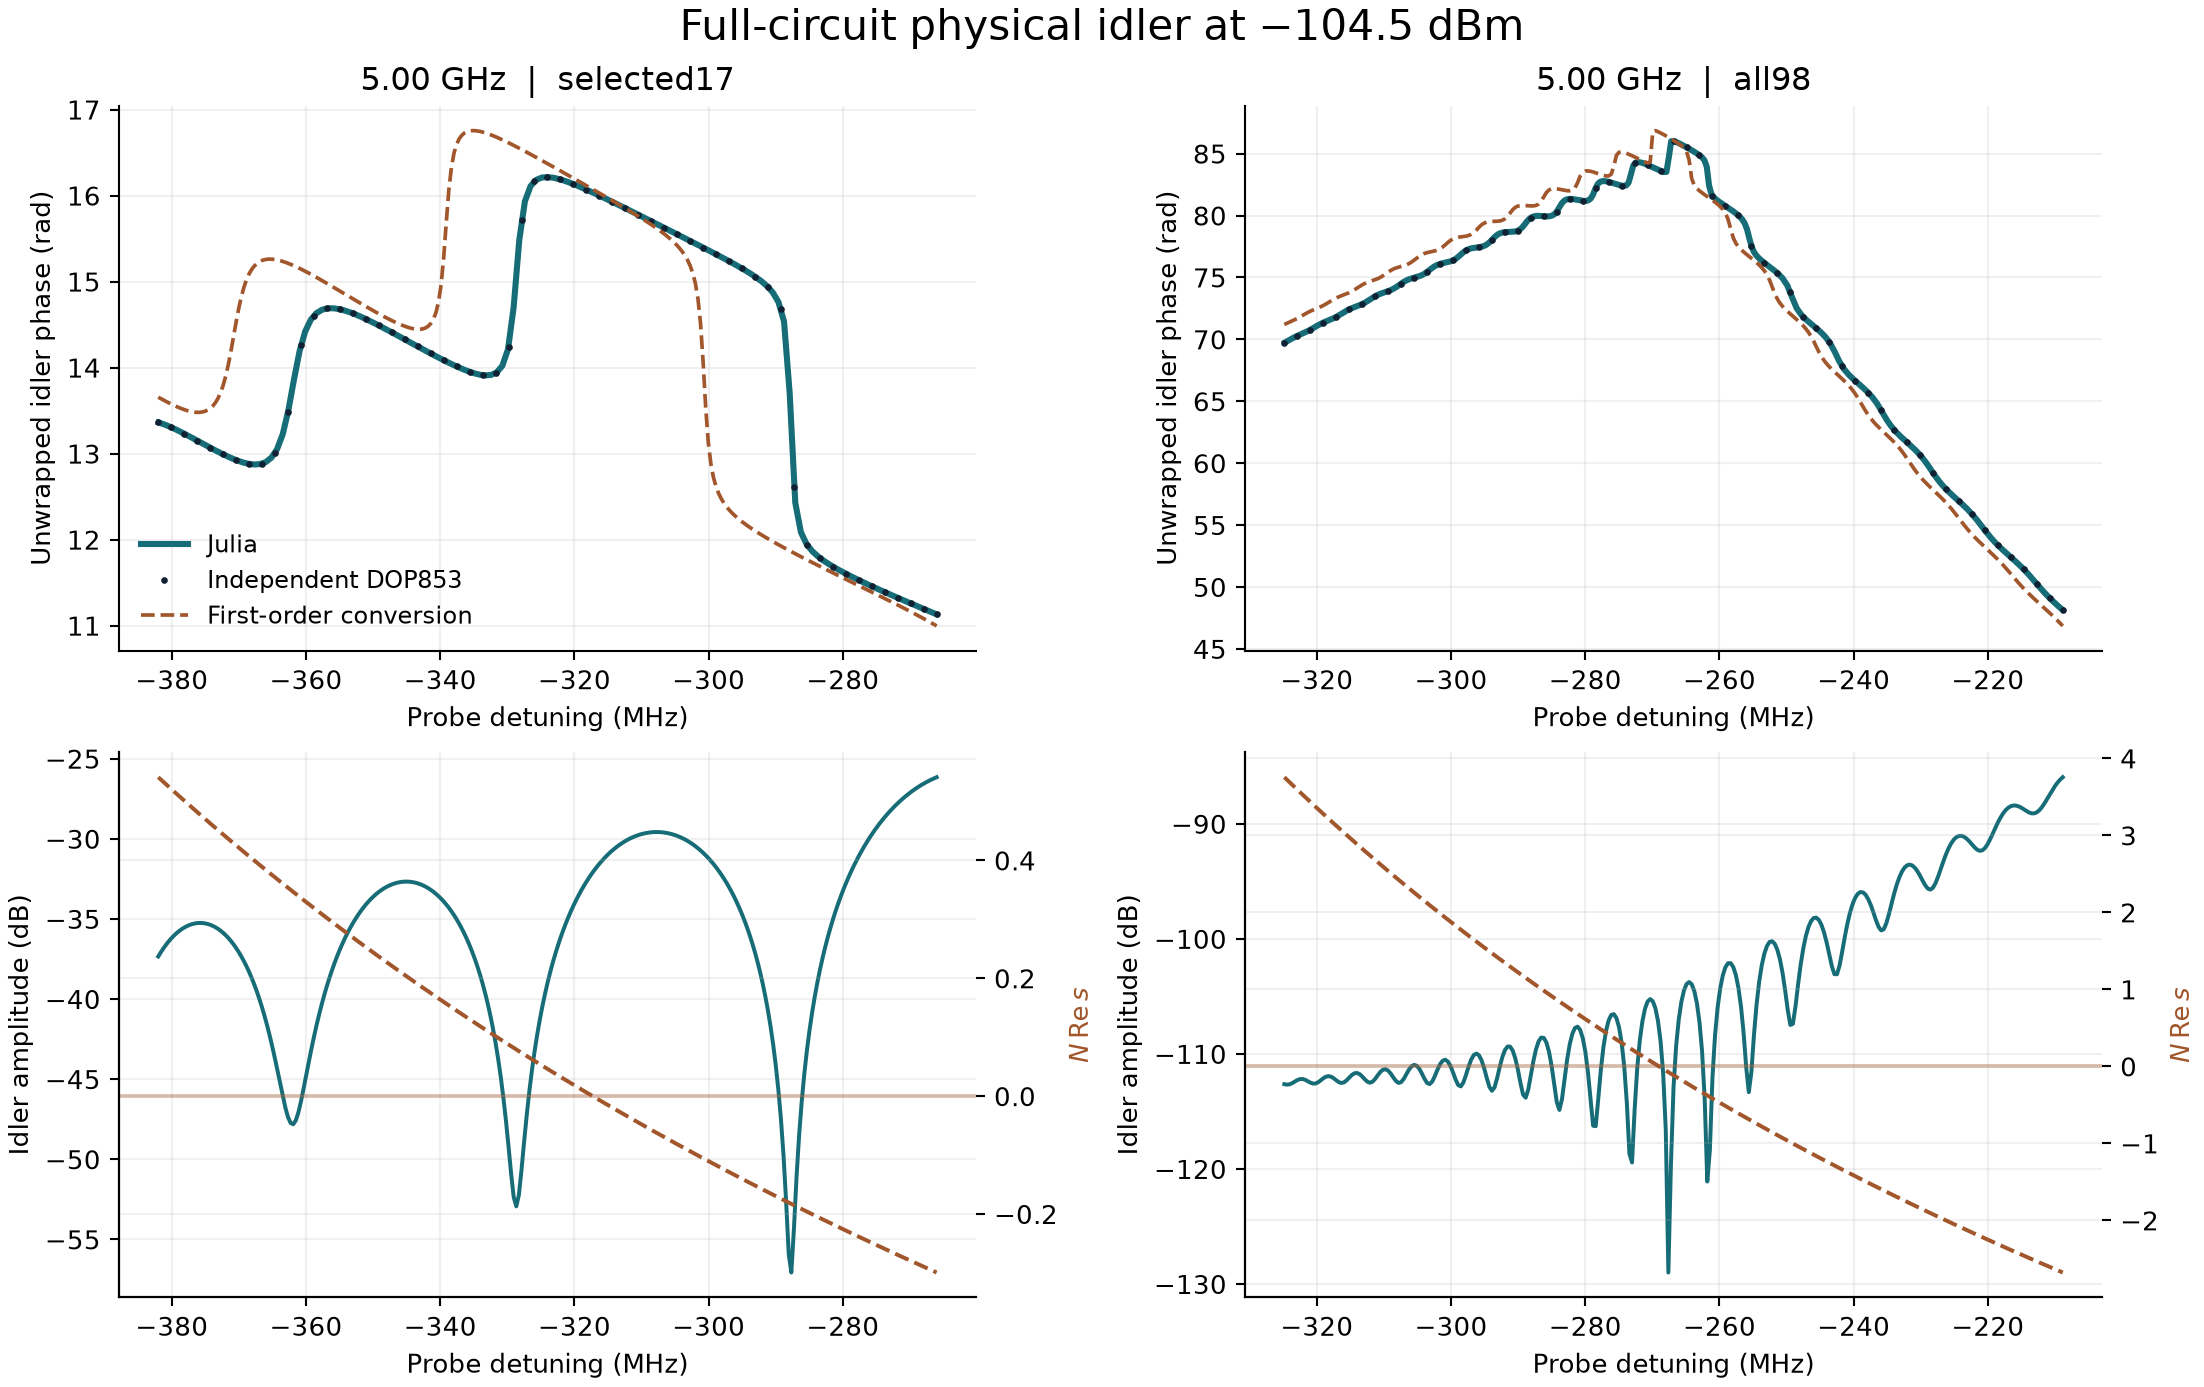

In [ ]:
display(FigurePNG(read(joinpath(pwd(), "Idler_Check.png"))))

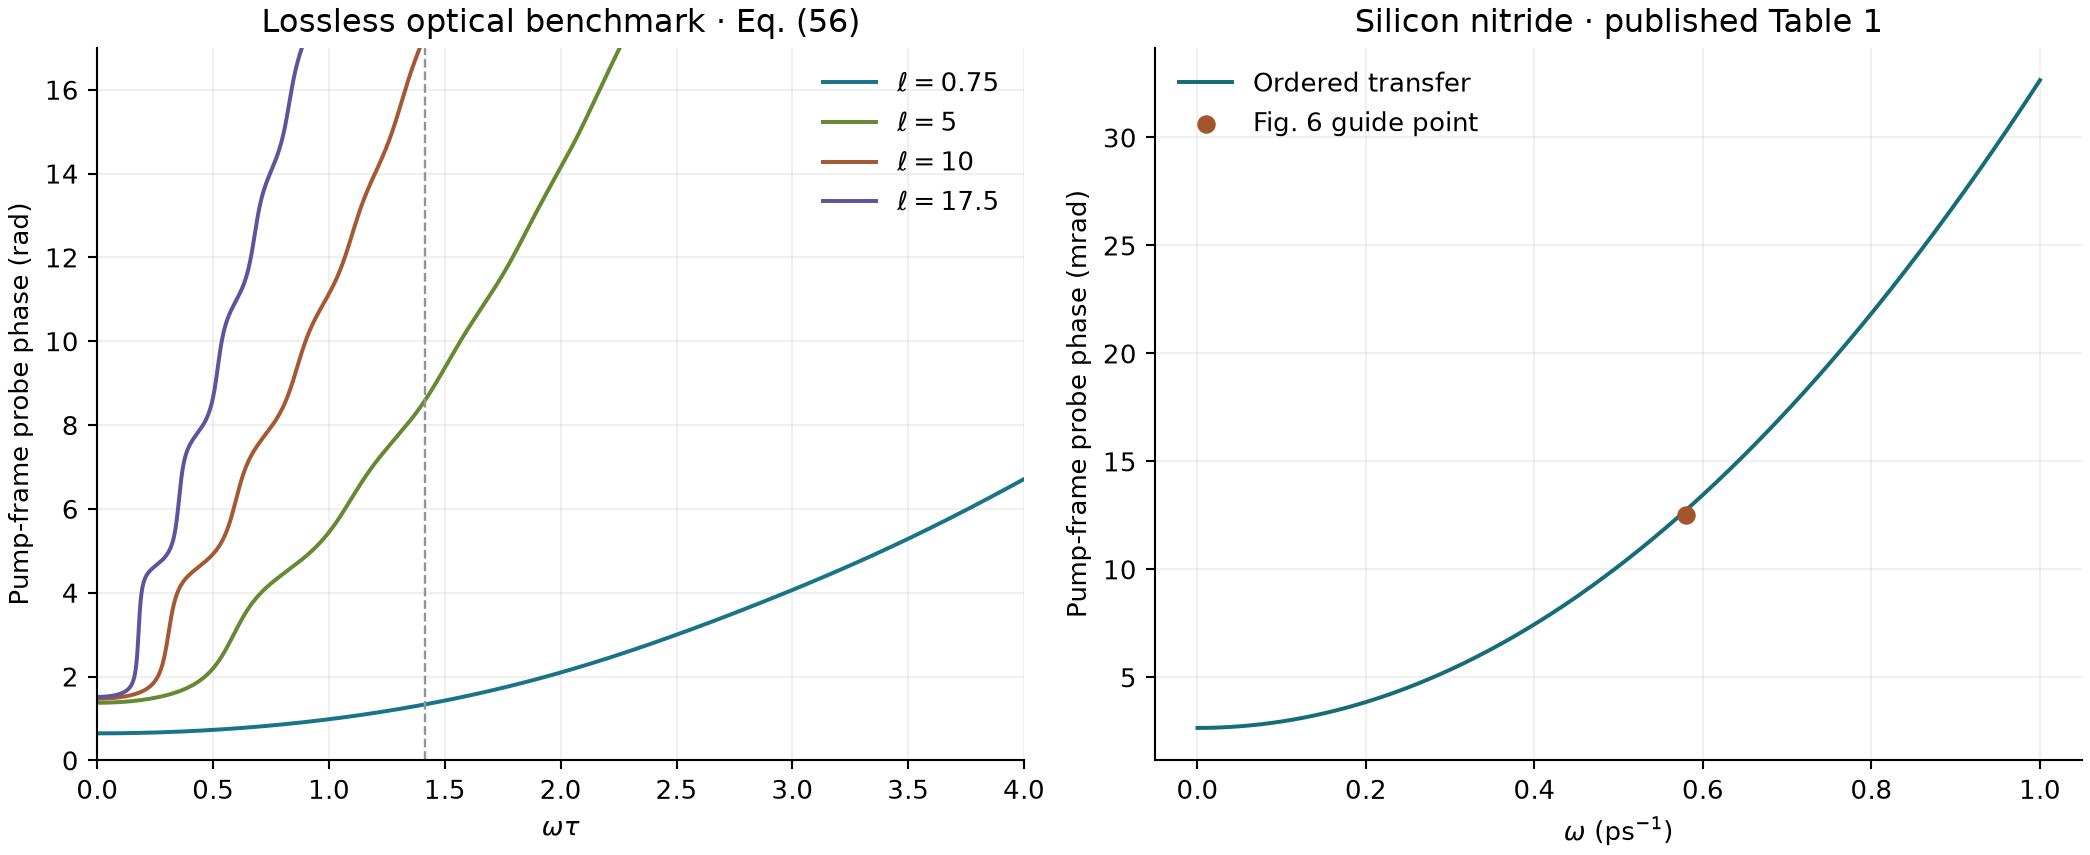

In [ ]:
display(FigurePNG(read(joinpath(pwd(), "Optical.png"))))